# 3.3 회귀·Z 점수 구간 및 가격·거래량 임계값 비교

첨부한 `FDS_regression_model_2025_current(2).ipynb`의 **81개 후보**를 현재 프로젝트의 계산 함수로 비교한다.

| 변경 항목 | 후보 |
|---|---|
| 회귀 구간 | 60 / 120 / 180거래일 |
| 가격·거래량 Z 기준 구간 | 40 / 60 / 120거래일 |
| 가격 임계값 | 절댓값 2.0 / 2.5 / 3.0 |
| 거래량 임계값 | 증가 방향 2.0 / 2.5 / 3.0 |

- **기간·기준 조합:** `run_config.json`에서 읽는다. 제공된 현재 실행 기록은 **2025-01-02~2026-10-08, 회귀 120 / Z 40 / 가격 2.5 / 거래량 2.5**이다. 첨부 실험 노트북에 남은 2026-09-17까지의 결과·가격 3.0 기준과 구분한다.
- **계산 조건:** 35개 고정 peer·6개 대상, 자기 제외·동일가중, 시장·순섹터 OLS, 일반 Z·표본 표준편차, `log1p` 거래량, 양방향 가격·증가 방향 거래량·OR, 30% 초과 필터와 판정 불가 처리는 **현재 모델 함수 그대로** 사용한다. 시장 보조 경보와 `volume_ratio_40d`의 40일 기준도 고정한다.
- **준비 자료:** 기존 2024년 입력은 유지한다. 180일 회귀+120일 과거 잔차에 필요한 준비 자료가 부족하면 첨부 코드와 같은 **2023-07-01**부터 앞부분만 별도 수집한다. 기존 자료와 겹치는 날짜의 가격·거래량이 일치하는지도 확인한다. 보충 자료는 분석 결과의 집계 기간에 포함하지 않는다.
- **같은 분모:** 9개 구간 조합 모두 판정 가능한 종목·거래일에서 비교한다. 판정 불가를 미경보로 세지 않는다. 제외된 행 수·날짜는 코드 셀 3에서 확인한다.
- RMSE·MAE는 **당일 실제 수익률과 장 마감 후 기대 수익률 사이의 잔차 크기**다. 경보 건수·겹침률·기업별 분포는 설정의 영향을 보여 주며, 정답 라벨이 없는 상태에서 탐지 정확도나 최적 설정으로 해석하지 않는다.

**실행:** 이 파일을 `FDS_regression_model` 또는 그 안의 `experiments`에 두고 기존 `aicam` 커널에서 Run All. 다른 위치라면 셀 1의 `MODEL_DIR`만 지정한다. 기존 프로젝트를 `python -m pip install -e "./FDS_regression_model[data]"`로 설치한 환경과 `matplotlib`, `IPython`이 필요하다. 준비 자료 수집은 첫 실행에만 필요하며 이후에는 저장된 자료를 재사용한다.

**보고서 중심 셀:** **3(기간·표본), 4(구간), 5(임계값), 6(설정별 변화·기업·기간), 7(그림), 8(변경 사례)**. 셀 9에서 표·전체 탐지 날짜·변경 사례·그림·실험 설정을 저장한다.

## 코드 셀 1 · 현재 실행 조건 확인
기존 실행과 같은 입력 파일·모델 설정인지 확인한다. 후보는 첨부 코드와 같다. 운영 설정 파일은 바꾸지 않는다.

In [1]:
from pathlib import Path
from types import SimpleNamespace
from itertools import product
import contextlib, hashlib, io, json, platform, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

MODEL_DIR = None  # 필요하면 Path(r"C:\ai_campus_mini_proj\FDS_regression_model")
EXTEND_PREPARATION = True  # True: 최대 구간도 같은 분석 시작일부터 비교하도록 앞부분 보충
if MODEL_DIR is None:
    choices = [p / name for p in [Path.cwd(), *Path.cwd().parents]
               for name in ("", "FDS_regression_model")]
    MODEL_DIR = next((p for p in choices if (p / "semiconductor_model/core.py").is_file()), None)
if MODEL_DIR is None:
    raise FileNotFoundError("MODEL_DIR에 FDS_regression_model 경로를 지정하세요.")
MODEL_DIR = Path(MODEL_DIR).resolve()
sys.path.insert(0, str(MODEL_DIR))
from semiconductor_model import core
from semiconductor_model.config import CONFIG
from semiconductor_model.data import read_inputs, build_panel
assert Path(core.__file__).resolve().parents[1] == MODEL_DIR, "커널을 재시작하고 다시 실행하세요."
run = json.loads((MODEL_DIR / "run_config.json").read_text(encoding="utf-8"))
assert CONFIG.to_dict() == run["model"], "모델 설정과 실행 기록이 다릅니다. 기존 모델을 먼저 실행하세요."
START, END = pd.Timestamp(run["analysis_start"]), pd.Timestamp(run["analysis_end"])
DATA, OUT = MODEL_DIR / "data", MODEL_DIR / "experiments" / "3_3_settings"
names = ["stocks.csv", "markets.csv", "calendar.csv", "universe.csv"]
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes = {n: sha(DATA / n) for n in names}
assert input_hashes == run["inputs"]["sha256"], "입력 파일이 실행 기록과 다릅니다. 기존 모델을 먼저 실행하세요."
stocks, markets, calendar, universe = read_inputs(DATA, END)
original_panel = build_panel(stocks, markets, calendar, universe, CONFIG)
R_WINDOWS, Z_WINDOWS = [60, 120, 180], [40, 60, 120]
P_THRESHOLDS, V_THRESHOLDS = [2.0, 2.5, 3.0], [2.0, 2.5, 3.0]
REF = (CONFIG.train_window, CONFIG.z_window, CONFIG.price_threshold, CONFIG.volume_threshold)
exp_id = lambda r, z, p, v: f"R{r}_Z{z}_P{p:.1f}_V{v:.1f}"
REF_ID = exp_id(*REF)
display(pd.DataFrame({"항목": ["분석 기간", "기준 조합", "후보 수", "대상 / peer", "입력 검증"],
    "값": [f"{START.date()} ~ {END.date()}", REF_ID, "3 × 3 × 3 × 3 = 81",
           f"{universe.is_target.sum()} / {universe.is_peer.sum()}", "현재 실행 기록과 일치"]}))

,항목,값
0,분석 기간,2025-01-02 ~ 2026-10-08
1,기준 조합,R120_Z40_P2.5_V2.5
2,후보 수,3 × 3 × 3 × 3 = 81
3,대상 / peer,6 / 35
4,입력 검증,현재 실행 기록과 일치


## 코드 셀 2 · 준비 자료 확인·보충 및 입력 구성
최대 구간은 분석 시작 전에 최소 **301개 가격 관측 거래일**이 필요하다. 부족할 때만 2023년 준비 자료를 수집한다. 기존 입력 파일은 수정하지 않으며, 수집 자료와 기존 자료의 겹치는 구간이 다르면 중단한다. 재수집으로 과거 수정주가가 달라졌을 때 서로 다른 가격 기준을 그대로 연결하는 것을 막기 위한 확인이다.

`EXTEND_PREPARATION=False`로 하면 추가 수집 없이 실행할 수 있지만 긴 구간의 초기 날짜가 비교에서 제외될 수 있다. 이 경우 셀 3의 **실제 공통 비교 기간·제외 수**로 보고서를 작성해야 한다.

In [2]:
needed = max(R_WINDOWS) + max(Z_WINDOWS) + 1
existing_prep_days = int(calendar.date.lt(START).sum())
prep_hashes, overlap_checks = {}, []
panel = original_panel.copy()
if existing_prep_days < needed and EXTEND_PREPARATION:
    from semiconductor_model.download_data import download_inputs
    PREP = OUT / "preparation_data"
    overlap_end = calendar.date.min() + pd.Timedelta(days=14)
    print("최대 구간용 준비 자료 확인 · 처음에는 37개 종목·두 지수를 별도 수집합니다.")
    if not (PREP / "data_manifest.json").exists():
        with contextlib.redirect_stdout(io.StringIO()):
            download_inputs(PREP, start="2023-07-01", end=str(overlap_end.date()))
    prep_manifest = json.loads((PREP / "data_manifest.json").read_text(encoding="utf-8"))
    prep_hashes = {n: sha(PREP / n) for n in names}
    assert prep_hashes == prep_manifest["sha256"], "보충 자료가 수집 이후 변경되었습니다."
    ps, pm, pc, pu = read_inputs(PREP, overlap_end)
    assert pc.date.min() < calendar.date.min(), "보충 자료에 이전 거래일이 없습니다."
    overlap_dates = calendar.loc[calendar.date.le(overlap_end), "date"]
    for old, new, keys, cols, label in [(stocks, ps, ["date", "code"], ["close", "volume"], "종목"),
                                       (markets, pm, ["date", "market"], ["close"], "지수")]:
        a = old.loc[old.date.isin(overlap_dates)].set_index(keys)[cols].sort_index()
        b = new.loc[new.date.isin(overlap_dates)].set_index(keys)[cols].sort_index()
        assert a.index.equals(b.index), f"{label}: 보충 자료의 겹치는 구간에 관측이 누락되었습니다."
        np.testing.assert_allclose(a.to_numpy(), b.to_numpy(), rtol=1e-10, atol=1e-8, equal_nan=True,
            err_msg=f"{label}: 과거 가격·거래량이 기존 입력과 다릅니다. 같은 시점에 수집한 일관된 자료를 확보하세요.")
        overlap_checks.append({"input": label, "checked_rows": len(a), "result": "PASS"})
    first = calendar.date.min()
    merge_past = lambda past, current: pd.concat([past.loc[past.date.lt(first)], current], ignore_index=True)
    stocks, markets, calendar = merge_past(ps, stocks), merge_past(pm, markets), merge_past(pc, calendar)
    panel = build_panel(stocks, markets, calendar, universe, CONFIG)
    assert int(calendar.date.lt(START).sum()) >= needed, "최대 구간을 위한 준비 자료가 여전히 부족합니다."
print(f"입력: {calendar.date.min().date()} ~ {calendar.date.max().date()} / 분석 전 준비 거래일 {int(calendar.date.lt(START).sum())}일")
if existing_prep_days < needed and not EXTEND_PREPARATION:
    print("보충 수집 OFF: 긴 구간의 초기 판정 불가를 미경보로 세지 않고 공통 비교 표본에서 제외합니다.")

최대 구간용 준비 자료 확인 · 처음에는 37개 종목·두 지수를 별도 수집합니다.
입력: 2023-07-03 ~ 2026-10-08 / 분석 전 준비 거래일 366일


## 코드 셀 3 · 9개 구간 계산·현재 기준 재현·공통 표본 [보고서: 실험 조건]
실험용 객체로 구간만 바꾸어 `core.detect()`를 실행한다. 임계값 비교는 이미 계산된 점수에 적용하므로 회귀를 81번 반복하지 않는다. 원래 준비 자료와 보충 자료를 사용한 기준 조합의 **분석 기간 전체 점수·판정이 동일한지** 확인한다.

**공통 비교 행 수**가 이후 모든 표의 분모다. 일부 날짜가 제외되면 `excluded_samples.csv`에 해당 종목·날짜를 남긴다. 보고용 연도·반기는 학습·테스트 분할이 아니다.

In [3]:
scored = {}
for r in R_WINDOWS:
    for z in Z_WINDOWS:
        cfg = SimpleNamespace(**{**CONFIG.to_dict(), "train_window": r, "z_window": z})
        full = core.detect(panel, cfg)
        scored[(r, z)] = full.loc[full.date.between(START, END)].set_index(["date", "code"]).sort_index()
    print(f"회귀 {r}일 × Z 3개 구간 계산 완료")
original = core.detect(original_panel, CONFIG)
original = original.loc[original.date.between(START, END)].set_index(["date", "code"]).sort_index()
baseline_full = scored[REF[:2]]
check_cols = ["expected_return", "price_residual", "price_z", "volume_z", "volume_ratio_40d",
              "price_alert", "volume_alert", "alert_type", "decision_status"]
pd.testing.assert_frame_equal(original[check_cols], baseline_full[check_cols], atol=1e-12, rtol=1e-12)
assert len(original) == run["rows"], "현재 실행과 분석 행 수가 다릅니다."
assert int((original.price_alert | original.volume_alert).sum()) == run["stock_alert_json_count"]
validity = pd.DataFrame({f"R{r}_Z{z}": f.decision_status.eq("OK") & np.isfinite(f.price_z) & np.isfinite(f.volume_z)
                        for (r, z), f in scored.items()})
common = validity.all(axis=1)
if not common.any():
    raise ValueError("9개 구간의 공통 유효 표본이 없습니다. 준비 자료와 결측을 확인하세요.")
coverage_by_setting = pd.DataFrame({"valid_rows": validity.sum(), "requested_rows": len(validity)})
coverage_by_setting["excluded_rows"] = coverage_by_setting.requested_rows - coverage_by_setting.valid_rows
sample_info = baseline_full[["name"]].assign(common_valid=common).reset_index()
coverage_by_company = sample_info.groupby(["code", "name"]).agg(
    requested_rows=("common_valid", "size"), common_rows=("common_valid", "sum")).reset_index()
coverage_by_company["excluded_rows"] = coverage_by_company.requested_rows - coverage_by_company.common_rows
excluded_samples = sample_info.loc[~sample_info.common_valid].merge(validity.reset_index(), on=["date", "code"])
comparison_start = sample_info.loc[sample_info.common_valid, "date"].min()
comparison_end = sample_info.loc[sample_info.common_valid, "date"].max()
features = {k: f.loc[common].reset_index() for k, f in scored.items()}
print(f"기준 조합 재현 PASS / 공통 비교 {int(common.sum()):,}개 종목·거래일 / 제외 {int((~common).sum()):,}행")
print(f"실제 공통 비교 범위: {comparison_start.date()} ~ {comparison_end.date()}")
display(coverage_by_setting, coverage_by_company)

회귀 60일 × Z 3개 구간 계산 완료
회귀 120일 × Z 3개 구간 계산 완료
회귀 180일 × Z 3개 구간 계산 완료
기준 조합 재현 PASS / 공통 비교 2,574개 종목·거래일 / 제외 0행
실제 공통 비교 범위: 2025-01-02 ~ 2026-10-08


,valid_rows,requested_rows,excluded_rows
R60_Z40,2574,2574,0
R60_Z60,2574,2574,0
R60_Z120,2574,2574,0
R120_Z40,2574,2574,0
R120_Z60,2574,2574,0
R120_Z120,2574,2574,0
R180_Z40,2574,2574,0
R180_Z60,2574,2574,0
R180_Z120,2574,2574,0


,code,name,requested_rows,common_rows,excluded_rows
0,000660,SK하이닉스,429,429,0
1,000990,DB하이텍,429,429,0
2,005930,삼성전자,429,429,0
3,036930,주성엔지니어링,429,429,0
4,042700,한미반도체,429,429,0
5,240810,원익IPS,429,429,0


## 코드 셀 4 · 회귀 구간과 Z 기준 구간 [보고서: 구간 선정 근거]
첫 표는 **회귀 구간**에 따른 잔차 RMSE·MAE, 다음 표는 **9개 회귀·Z 조합**의 경보 비율이다. RMSE·MAE는 %p 단위로 표시하며 변화율은 기준 회귀 구간 대비 상대적 %이다. Z 구간은 이미 계산된 잔차의 표준화 기준만 바꾸므로 같은 회귀 구간의 RMSE·MAE를 바꾸지 않는다.

전체 81개 조합을 먼저 집계하되, 화면에는 비교에 필요한 표만 보여 준다. 가격·거래량 경보가 겹치므로 두 건수를 더해 OR 건수로 사용하지 않는다.

In [4]:
def describe(f, p, v):
    price, volume = f.price_z.abs().ge(p), f.volume_z.ge(v)
    alert = price | volume
    by_company = f.assign(alert=alert).groupby("code").alert.agg(["mean", "sum"])
    return {"n": len(f), "price_alerts": int(price.sum()), "volume_alerts": int(volume.sum()),
            "both_alerts": int((price & volume).sum()), "or_alerts": int(alert.sum()),
            "price_rate_pct": 100 * price.mean(), "volume_rate_pct": 100 * volume.mean(),
            "or_rate_pct": 100 * alert.mean(), "max_company_rate_pct": 100 * by_company["mean"].max(),
            "company_rate_spread_pp": 100 * (by_company["mean"].max() - by_company["mean"].min())}

rows = []
for r, z, p, v in product(R_WINDOWS, Z_WINDOWS, P_THRESHOLDS, V_THRESHOLDS):
    rows.append({"experiment_id": exp_id(r, z, p, v), "regression_days": r, "z_days": z,
                 "price_threshold": p, "volume_threshold": v, **describe(features[(r, z)], p, v)})
summary = pd.DataFrame(rows)
regression_summary = pd.DataFrame([{"regression_days": r, "n": len(features[(r, REF[1])]),
    "rmse_pp": 100 * np.sqrt(np.mean(features[(r, REF[1])].price_residual ** 2)),
    "mae_pp": 100 * features[(r, REF[1])].price_residual.abs().mean()} for r in R_WINDOWS])
ref_error = regression_summary.set_index("regression_days").loc[REF[0]]
for col in ["rmse", "mae"]:
    regression_summary[col + "_change_pct"] = 100 * (regression_summary[col + "_pp"] / ref_error[col + "_pp"] - 1)
regression_by_company = pd.concat([features[(r, REF[1])].groupby(["code", "name"]).price_residual.agg(
    rmse_pp=lambda x: 100 * np.sqrt(np.mean(x ** 2)), mae_pp=lambda x: 100 * x.abs().mean()
    ).reset_index().assign(regression_days=r) for r in R_WINDOWS], ignore_index=True)
window_summary = summary.loc[summary.price_threshold.eq(REF[2]) & summary.volume_threshold.eq(REF[3])].copy()
display(regression_summary.round(4))
display(regression_by_company.pivot(index="name", columns="regression_days", values="rmse_pp").round(4))
display(window_summary[["regression_days", "z_days", "n", "price_rate_pct", "volume_rate_pct", "or_rate_pct"]].round(3))

,regression_days,n,rmse_pp,mae_pp,rmse_change_pct,mae_change_pct
0,60,2574,3.5027,2.2159,1.7786,1.9118
1,120,2574,3.4415,2.1743,0.0000,0.0000
2,180,2574,3.4364,2.1555,-0.1477,-0.8664


regression_days,60,120,180
name,,,
DB하이텍,3.5762,3.4915,3.4674
SK하이닉스,2.3027,2.2947,2.2690
삼성전자,1.5654,1.5829,1.5961
원익IPS,3.8398,3.7215,3.7427
주성엔지니어링,4.6976,4.6602,4.6638
한미반도체,4.0325,3.9414,3.9213


,regression_days,z_days,n,price_rate_pct,volume_rate_pct,or_rate_pct
4,60,40,2574,3.147,3.147,4.934
13,60,60,2574,3.108,2.564,4.390
22,60,120,2574,3.341,2.603,4.740
31,120,40,2574,3.652,3.147,5.361
40,120,60,2574,3.225,2.564,4.507
49,120,120,2574,3.497,2.603,4.856
58,180,40,2574,3.574,3.147,5.245
67,180,60,2574,3.147,2.564,4.468
76,180,120,2574,3.652,2.603,5.012


## 코드 셀 5 · 가격·거래량 임계값 [보고서: 임계값 선정 근거]
현재 기준 회귀·Z 구간에서 **9개 임계값 조합**을 비교한다. 임계값은 잔차나 점수를 바꾸지 않고 경보 여부만 바꾼다. 마지막 두 열은 기업별 OR 경보 비율의 최대값과 최대·최소 차이(%p)다. 기업마다 실제 움직임이 다르므로 분포가 고르다는 이유만으로 더 좋은 설정으로 판단하지 않는다.

In [5]:
threshold_summary = summary.loc[summary.regression_days.eq(REF[0]) & summary.z_days.eq(REF[1])].copy()
display(threshold_summary[["price_threshold", "volume_threshold", "n", "price_alerts", "volume_alerts",
    "both_alerts", "or_alerts", "or_rate_pct", "max_company_rate_pct", "company_rate_spread_pp"]].round(3))
print(f"현재 기준: {REF_ID} · 임계값이 낮아져 늘어난 경보의 유용성은 변경 사례와 관련 자료로 검토합니다.")

,price_threshold,volume_threshold,n,price_alerts,volume_alerts,both_alerts,or_alerts,or_rate_pct,max_company_rate_pct,company_rate_spread_pp
27,2.0,2.0,2574,162,152,71,243,9.441,10.256,2.098
28,2.0,2.5,2574,162,81,49,194,7.537,8.392,1.865
29,2.0,3.0,2574,162,38,30,170,6.605,7.692,1.865
30,2.5,2.0,2574,94,152,53,193,7.498,9.324,3.730
31,2.5,2.5,2574,94,81,37,138,5.361,6.993,3.730
32,2.5,3.0,2574,94,38,24,108,4.196,5.361,3.030
33,3.0,2.0,2574,60,152,41,171,6.643,8.858,3.963
34,3.0,2.5,2574,60,81,32,109,4.235,6.061,3.730
35,3.0,3.0,2574,60,38,22,76,2.953,4.429,3.263


현재 기준: R120_Z40_P2.5_V2.5 · 임계값이 낮아져 늘어난 경보의 유용성은 변경 사례와 관련 자료로 검토합니다.


## 코드 셀 6 · 한 항목씩 바꾼 민감도·기업별·기간별 결과 [보고서: 설정 선택]
기준 조합에서 **한 항목만 변경한 8개 후보+기준**을 표시하여 여러 설정이 동시에 바뀌는 영향을 구분한다. `added/removed`는 OR 경보가 신규·해제된 종목·거래일 수이고, `price_changed/volume_changed`는 각 경로의 판정 변경 수다. `jaccard_pct`는 OR 경보 집합의 교집합/합집합 비율이다. 탐지 정확도를 뜻하지 않는다.

기업별 표와 기간별 표는 분모를 보정한 OR 경보 비율(%)이다. 전체 81개 조합의 상세 수치는 셀 9에서 저장한다.

In [6]:
def decision(f, p, v):
    d = f.copy()
    d["price_alert"], d["volume_alert"] = d.price_z.abs().ge(p), d.volume_z.ge(v)
    d["or_alert"] = d.price_alert | d.volume_alert
    d["alert_type"] = np.select([d.price_alert & d.volume_alert, d.price_alert, d.volume_alert],
                               ["PRICE_AND_VOLUME", "PRICE_ONLY", "VOLUME_ONLY"], default="NO_ALERT")
    d["period"] = np.where(d.date.dt.year.eq(2025), "2025", d.date.dt.year.astype(str) + np.where(d.date.dt.month.le(6), "H1", "H2"))
    return d.set_index(["date", "code"]).sort_index()

baseline = decision(features[REF[:2]], REF[2], REF[3])
diagnostics, company_parts, period_parts, event_parts, change_parts = [], [], [], [], []
for row in summary.itertuples(index=False):
    params = (row.regression_days, row.z_days, row.price_threshold, row.volume_threshold)
    d = decision(features[params[:2]], *params[2:])
    assert d.index.equals(baseline.index)
    kept, added, removed = d.or_alert & baseline.or_alert, d.or_alert & ~baseline.or_alert, ~d.or_alert & baseline.or_alert
    union = d.or_alert | baseline.or_alert
    price_changed, volume_changed = d.price_alert.ne(baseline.price_alert), d.volume_alert.ne(baseline.volume_alert)
    diagnostics.append({"experiment_id": row.experiment_id, "parameters_changed": sum(a != b for a, b in zip(params, REF)),
        "kept": int(kept.sum()), "added": int(added.sum()), "removed": int(removed.sum()),
        "price_changed": int(price_changed.sum()), "volume_changed": int(volume_changed.sum()),
        "jaccard_pct": 100 * kept.sum() / union.sum() if union.any() else np.nan})
    company = d.reset_index().groupby(["code", "name"]).agg(n=("or_alert", "size"), or_alerts=("or_alert", "sum"))
    company["or_rate_pct"] = 100 * company.or_alerts / company.n
    company_parts.append(company.reset_index().assign(experiment_id=row.experiment_id))
    period = d.reset_index().groupby("period").agg(n=("or_alert", "size"), price_alerts=("price_alert", "sum"),
        volume_alerts=("volume_alert", "sum"), or_alerts=("or_alert", "sum"))
    for signal in ["price", "volume", "or"]:
        period[signal + "_rate_pct"] = 100 * period[signal + "_alerts"] / period.n
    period_parts.append(period.reset_index().assign(experiment_id=row.experiment_id))
    event_parts.append(d.loc[d.or_alert, ["name", "stock_return", "expected_return", "price_residual", "price_z",
        "volume_z", "price_alert", "volume_alert", "alert_type"]].reset_index().assign(experiment_id=row.experiment_id))
    changed = price_changed | volume_changed
    c = d.loc[changed, ["name", "stock_return", "expected_return", "price_residual", "price_z", "volume_z", "alert_type"]].copy()
    c["baseline_type"], c["baseline_price_z"], c["baseline_volume_z"] = baseline.loc[changed, "alert_type"], baseline.loc[changed, "price_z"], baseline.loc[changed, "volume_z"]
    c["change"] = np.select([added.loc[changed], removed.loc[changed]], ["ADDED", "REMOVED"], default="TYPE_CHANGED")
    change_parts.append(c.reset_index().assign(experiment_id=row.experiment_id))
diagnostics = summary.merge(pd.DataFrame(diagnostics), on="experiment_id", validate="one_to_one")
one_factor = diagnostics.loc[diagnostics.parameters_changed.le(1)].copy()
company_summary, period_summary = pd.concat(company_parts, ignore_index=True), pd.concat(period_parts, ignore_index=True)
alert_dates, changed_cases = pd.concat(event_parts, ignore_index=True), pd.concat(change_parts, ignore_index=True)
display(one_factor[["experiment_id", "or_alerts", "or_rate_pct", "added", "removed", "price_changed", "volume_changed", "jaccard_pct"]].round(3))
display(company_summary.loc[company_summary.experiment_id.isin(one_factor.experiment_id)].pivot(
    index="experiment_id", columns="name", values="or_rate_pct").round(3))
display(period_summary.loc[period_summary.experiment_id.isin(one_factor.experiment_id)].pivot(
    index="experiment_id", columns="period", values="or_rate_pct").round(3))

,experiment_id,or_alerts,or_rate_pct,added,removed,price_changed,volume_changed,jaccard_pct
4,R60_Z40_P2.5_V2.5,127,4.934,6,17,27,0,84.028
28,R120_Z40_P2.0_V2.5,194,7.537,56,0,68,0,71.134
30,R120_Z40_P2.5_V2.0,193,7.498,55,0,0,71,71.503
31,R120_Z40_P2.5_V2.5,138,5.361,0,0,0,0,100.000
32,R120_Z40_P2.5_V3.0,108,4.196,0,30,0,43,78.261
34,R120_Z40_P3.0_V2.5,109,4.235,0,29,34,0,78.986
40,R120_Z60_P2.5_V2.5,116,4.507,12,34,23,33,69.333
49,R120_Z120_P2.5_V2.5,125,4.856,29,42,48,50,57.485
58,R180_Z40_P2.5_V2.5,135,5.245,3,6,14,0,93.617


name,DB하이텍,SK하이닉스,삼성전자,원익IPS,주성엔지니어링,한미반도체
experiment_id,,,,,,
R120_Z120_P2.5_V2.5,5.828,2.098,3.030,5.828,7.226,5.128
R120_Z40_P2.0_V2.5,8.392,6.527,7.692,6.760,7.925,7.925
R120_Z40_P2.5_V2.0,7.925,5.594,7.226,6.993,7.925,9.324
R120_Z40_P2.5_V2.5,6.061,3.263,5.594,4.662,5.594,6.993
R120_Z40_P2.5_V3.0,5.361,2.331,3.963,3.730,4.429,5.361
R120_Z40_P3.0_V2.5,5.128,2.331,2.797,4.429,4.662,6.061
R120_Z60_P2.5_V2.5,6.294,1.399,3.730,5.128,5.128,5.361
R180_Z40_P2.5_V2.5,6.061,3.497,5.361,4.662,5.361,6.527
R60_Z40_P2.5_V2.5,6.294,3.030,3.963,4.662,5.128,6.527


period,2025,2026H1,2026H2
experiment_id,,,
R120_Z120_P2.5_V2.5,4.270,7.639,1.990
R120_Z40_P2.0_V2.5,7.369,9.722,4.229
R120_Z40_P2.5_V2.0,7.094,10.000,4.478
R120_Z40_P2.5_V2.5,4.959,7.222,3.483
R120_Z40_P2.5_V3.0,3.926,5.833,2.239
R120_Z40_P3.0_V2.5,3.926,5.694,2.736
R120_Z60_P2.5_V2.5,4.477,5.556,2.736
R180_Z40_P2.5_V2.5,4.752,7.222,3.483
R60_Z40_P2.5_V2.5,4.408,6.806,3.483


## 코드 셀 7 · 보고서용 그림
왼쪽은 회귀 구간별 잔차 RMSE, 가운데는 기준 임계값을 고정한 구간별 OR 경보 비율, 오른쪽은 기준 구간을 고정한 임계값별 OR 경보 비율이다. 빨간 테두리는 현재 기준 조합이다. 그래프의 낮은 값만으로 설정을 자동 선정하지 않는다.

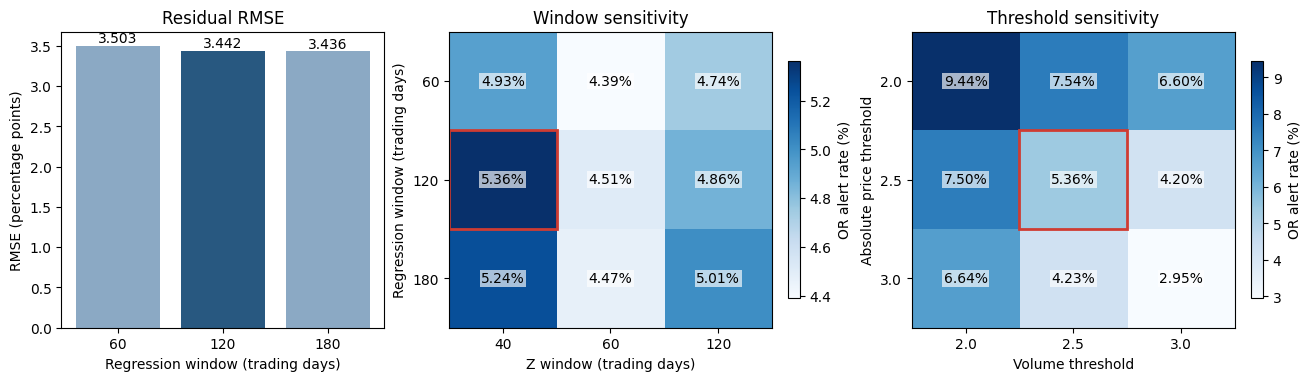

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
axes[0].bar(regression_summary.regression_days.astype(str), regression_summary.rmse_pp, color=["#8ba9c4", "#285880", "#8ba9c4"])
axes[0].set(title="Residual RMSE", xlabel="Regression window (trading days)", ylabel="RMSE (percentage points)")
for i, value in enumerate(regression_summary.rmse_pp):
    axes[0].text(i, value, f"{value:.3f}", ha="center", va="bottom")
matrices = [window_summary.pivot(index="regression_days", columns="z_days", values="or_rate_pct"),
            threshold_summary.pivot(index="price_threshold", columns="volume_threshold", values="or_rate_pct")]
for ax, matrix, title, xlabel, ylabel, ref in zip(axes[1:], matrices,
    ["Window sensitivity", "Threshold sensitivity"], ["Z window (trading days)", "Volume threshold"],
    ["Regression window (trading days)", "Absolute price threshold"], [REF[:2], REF[2:]]):
    heat = ax.imshow(matrix.to_numpy(), cmap="Blues", aspect="auto")
    ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
           yticks=range(len(matrix.index)), yticklabels=matrix.index, title=title, xlabel=xlabel, ylabel=ylabel)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}%", ha="center", va="center", color="black",
                    bbox={"facecolor": "white", "alpha": 0.65, "edgecolor": "none", "pad": 1})
    i, j = list(matrix.index).index(ref[0]), list(matrix.columns).index(ref[1])
    ax.add_patch(Rectangle((j-.5, i-.5), 1, 1, fill=False, edgecolor="#cf3c32", linewidth=2))
    fig.colorbar(heat, ax=ax, label="OR alert rate (%)", shrink=0.8)
plt.show()

## 코드 셀 8 · 변경된 탐지 날짜 조회 [보고서: 선택 근거·사례]
아래 ID를 셀 6의 후보 ID로 바꾸어 **같은 표본에서 신규·해제·유형 변경**된 날짜를 확인한다. 기본값은 가격 임계값만 2.5→3.0으로 바꾼 비교다. 화면에는 10행만 출력하며 **전체 변경 목록은 `changed_cases.csv`, 전체 81개 조합의 탐지 날짜는 `alert_dates.csv`**에 저장한다. 관련 기사·공시의 유용성 평가는 이 코드가 자동 수행하지 않는다.

In [8]:
COMPARE_ID = exp_id(REF[0], REF[1], 3.0, REF[3])  # 예: "R60_Z40_P2.5_V2.5"
if COMPARE_ID not in set(summary.experiment_id):
    raise ValueError("셀 6에 표시된 후보 ID를 입력하세요.")
cases = changed_cases.loc[changed_cases.experiment_id.eq(COMPARE_ID)].sort_values(["date", "code"])
display(diagnostics.loc[diagnostics.experiment_id.eq(COMPARE_ID),
    ["experiment_id", "price_alerts", "volume_alerts", "or_alerts", "added", "removed", "price_changed", "volume_changed"]])
display(cases[["date", "code", "name", "change", "baseline_type", "alert_type", "baseline_price_z", "price_z", "volume_z"]].head(10).round(4))
print(f"전체 변경 {len(cases)}행 · 전체 날짜는 마지막 셀에서 CSV로 저장")

,experiment_id,price_alerts,volume_alerts,or_alerts,added,removed,price_changed,volume_changed
34,R120_Z40_P3.0_V2.5,60,81,109,0,29,34,0


,date,code,name,change,baseline_type,alert_type,baseline_price_z,price_z,volume_z
3233,2025-01-22,036930,주성엔지니어링,TYPE_CHANGED,PRICE_AND_VOLUME,VOLUME_ONLY,-2.5256,-2.5256,2.5346
3234,2025-01-22,042700,한미반도체,REMOVED,PRICE_ONLY,NO_ALERT,2.6516,2.6516,2.3994
3235,2025-01-31,000660,SK하이닉스,TYPE_CHANGED,PRICE_AND_VOLUME,VOLUME_ONLY,-2.5240,-2.5240,2.8905
3236,2025-02-10,005930,삼성전자,REMOVED,PRICE_ONLY,NO_ALERT,2.5282,2.5282,1.3184
3237,2025-02-14,036930,주성엔지니어링,TYPE_CHANGED,PRICE_AND_VOLUME,VOLUME_ONLY,2.9694,2.9694,3.5778
3238,2025-05-02,000660,SK하이닉스,REMOVED,PRICE_ONLY,NO_ALERT,2.8789,2.8789,0.4916
3239,2025-05-12,005930,삼성전자,REMOVED,PRICE_ONLY,NO_ALERT,2.5518,2.5518,-0.0680
3240,2025-05-28,005930,삼성전자,REMOVED,PRICE_ONLY,NO_ALERT,2.6167,2.6167,0.7548
3241,2025-06-16,005930,삼성전자,REMOVED,PRICE_ONLY,NO_ALERT,-2.9600,-2.9600,1.5728
3242,2025-06-26,042700,한미반도체,TYPE_CHANGED,PRICE_AND_VOLUME,VOLUME_ONLY,2.6627,2.6627,2.5823


전체 변경 34행 · 전체 날짜는 마지막 셀에서 CSV로 저장


## 코드 셀 9 · 표·그림·전체 날짜·설정 저장
`experiments/3_3_settings/results/`에 저장한다. 운영 CSV·경보 JSON·`run_config.json`은 수정하지 않는다. **`summary_81.csv`는 전체 조합, `one_factor_comparison.csv`는 보고서의 핵심 민감도 표**다. `company_summary.csv`, `period_summary.csv`는 기업·기간별 분모와 건수를 포함한다.

In [9]:
RESULTS = OUT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
tables = {"coverage_by_setting": coverage_by_setting.reset_index(names="window"), "coverage_by_company": coverage_by_company,
    "excluded_samples": excluded_samples, "regression_summary": regression_summary, "regression_by_company": regression_by_company,
    "window_summary": window_summary, "threshold_summary": threshold_summary, "summary_81": diagnostics,
    "one_factor_comparison": one_factor, "company_summary": company_summary, "period_summary": period_summary,
    "alert_dates": alert_dates, "changed_cases": changed_cases}
for name, frame in tables.items():
    frame.to_csv(RESULTS / f"{name}.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
fig.savefig(RESULTS / "comparison.png", dpi=200, bbox_inches="tight")
assert {n: sha(DATA / n) for n in names} == input_hashes, "현재 입력 파일이 실험 도중 변경되었습니다."
metadata = {"requested_analysis_start": str(START.date()), "requested_analysis_end": str(END.date()),
    "common_start": str(comparison_start.date()), "common_end": str(comparison_end.date()),
    "requested_rows": len(common), "common_rows": int(common.sum()), "excluded_rows": int((~common).sum()),
    "original_input_sha256": input_hashes, "preparation_input_sha256": prep_hashes, "overlap_checks": overlap_checks,
    "input_first_session": str(calendar.date.min().date()), "reference": CONFIG.to_dict(),
    "regression_windows": R_WINDOWS, "z_windows": Z_WINDOWS, "price_thresholds": P_THRESHOLDS,
    "volume_thresholds": V_THRESHOLDS, "experiment_count": len(summary), "observation_unit": "stock_trading_day",
    "implementation_sha256": {n: sha(MODEL_DIR / "semiconductor_model" / n) for n in ["core.py", "data.py", "config.py"]},
    "packages": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__}}
(RESULTS / "experiment_config.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"저장 완료: {RESULTS.resolve()}")
print("보고서 첨부: regression_summary / window_summary / threshold_summary / one_factor_comparison / comparison.png")
print("사례 검토: changed_cases.csv · 전체 탐지 날짜: alert_dates.csv · 기간·분모: experiment_config.json")

저장 완료: C:\ai_campus_mini_proj\FDS_regression_model\experiments\3_3_settings\results
보고서 첨부: regression_summary / window_summary / threshold_summary / one_factor_comparison / comparison.png
사례 검토: changed_cases.csv · 전체 탐지 날짜: alert_dates.csv · 기간·분모: experiment_config.json


### 보고서에 반영할 때
- 회귀 구간: 셀 4의 전체·기업별 RMSE·MAE와 셀 6의 경보 변화로 선택 근거를 제시한다.
- Z 구간: 셀 4·6에서 경보 비율과 날짜 변화, 기업·기간별 차이를 확인한다. Z 구간의 선정 근거로 RMSE 감소를 쓰지 않는다.
- 임계값: 셀 5·6의 경보 비율·기업별 분포와 셀 8의 추가·제외 사례를 연결한다. 건수가 적거나 많다는 사실만으로 탐지 품질을 확정하지 않는다.
- 현재 120/40/2.5/2.5를 유지하더라도 자동으로 최적값을 찾았다는 표현은 피한다. 실제 확인된 수치와 사례를 근거로 선택을 설명한다.